# **Section 6: K-Nearest Neighbors**

In this notebook, I will train and evaluate K-Nearest Neighbors (KNN) models. I will start by training a model with a default number of neighbors (k=5), and will then tune the number of neighbors using a cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic K-Nearest neighbour model**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Saving model results**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

## **1. Import data**
Let's load the training and test sets, and their corresponding resistance profiles.

In [2]:
# Load features and labels
snp_train = pd.read_csv("Data/snp_train_selected.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = snp_train.values
y_train = profiles_train.values

X_test = snp_test.values
y_test = profiles_test.values

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (176, 796)
Test set shape: (50, 796)
Categories: [0 1]


## **2. Basic K-Nearest Neighbors model**

### **2.1 Training and fitting the model**
Let's start with a baseline KNN model using default parameters (k=5).

In [3]:
# Create KNN pipeline with standardization
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,796
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training, validation, and test sets
accuracy_train = knn.score(X_train, y_train)
accuracy_test = knn.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.8750
Accuracy test set: 0.5400


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = knn.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.70      0.65        30
           1       0.40      0.30      0.34        20

    accuracy                           0.54        50
   macro avg       0.50      0.50      0.49        50
weighted avg       0.52      0.54      0.52        50



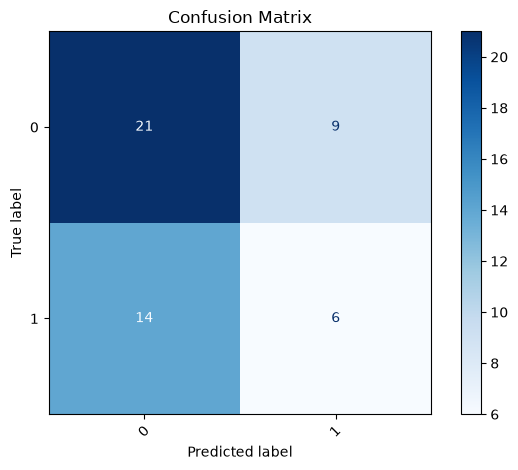

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

This model also isn't performing very well on the test set, but already better than the logistic regression. It look like it's mainly predicting "susceptible", and only rarely predicting "resistant". Let's try to otpimize the number of neighbors.

## **3. Hyperparameter tuning: optimizing k**

Now let's use cross-validated grid search to find the optimal number of neighbors.

### **3.1 Grid Search**

In [7]:
# Create KNN pipeline
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Define parameter grid
param_grid = {'kneighborsclassifier__n_neighbors': [1, 5, 10, 15, 20, 25, 30, 35, 40]}

# Create grid search object
grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Best parameters: {'kneighborsclassifier__n_neighbors': 20}
Best cross-validation score: 0.7278


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score', 
    'mean_train_score', 'std_train_score',
    'param_kneighborsclassifier__n_neighbors'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.721429        0.029277          0.995735         0.003483   
1         0.710476        0.114063          0.856555         0.026959   
2         0.704603        0.066281          0.808247         0.036668   
3         0.716349        0.054117          0.734377         0.015873   
4         0.727778        0.063694          0.741489         0.027750   

   param_kneighborsclassifier__n_neighbors  
0                                        1  
1                                        5  
2                                       10  
3                                       15  
4                                       20  


### **3.2 Visualize Training/Validation curves**

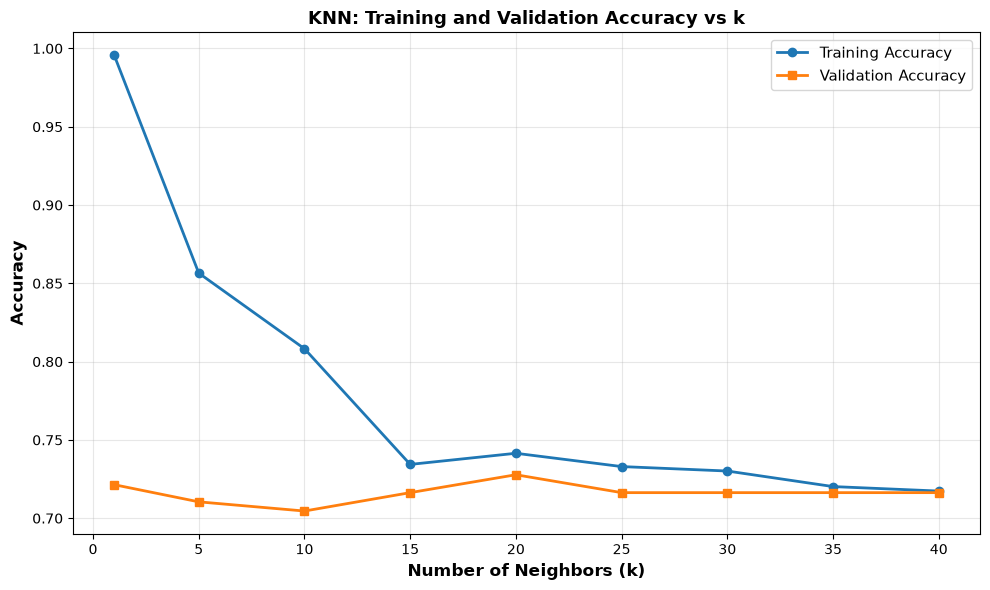

In [9]:
# Sort results by k value for plotting
cv_results_sorted = cv_results.sort_values('param_kneighborsclassifier__n_neighbors')

# Plot accuracy curves
plt.figure(figsize=(10, 6))
plt.plot(
    cv_results_sorted['param_kneighborsclassifier__n_neighbors'],
    cv_results_sorted['mean_train_score'],
    label='Training Accuracy',
    marker='o',
    linewidth=2
)
plt.plot(
    cv_results_sorted['param_kneighborsclassifier__n_neighbors'],
    cv_results_sorted['mean_test_score'],
    label='Validation Accuracy',
    marker='s',
    linewidth=2
)

plt.xlabel('Number of Neighbors (k)', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
plt.title('KNN: Training and Validation Accuracy vs k', fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/05_knn_training_curve", dpi=300)
plt.show()

The model seems to perform best when using 20 neighbours. We see that at this point, the performance of the validation is best, and the model also overfits the least. Let's try to see what the performance is on the test set now. 

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_knn = grid_search.best_estimator_
accuracy_test_best = best_knn.score(X_test, y_test)

print(f"\nBest model test accuracy: {accuracy_test_best:.4f}")
print(f"Best k value: {grid_search.best_params_['kneighborsclassifier__n_neighbors']}")


Best model test accuracy: 0.4000
Best k value: 20


We see that this model performs less well than before! 

### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_knn.predict(X_test)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_best))


Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.10      0.17        30
           1       0.39      0.85      0.53        20

    accuracy                           0.40        50
   macro avg       0.44      0.47      0.35        50
weighted avg       0.45      0.40      0.31        50



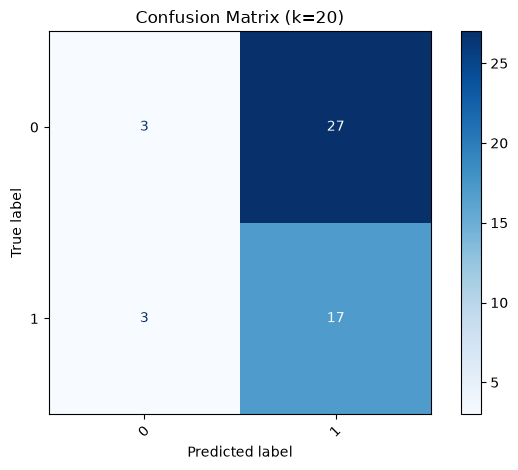

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_knn.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_knn.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (k={grid_search.best_params_['kneighborsclassifier__n_neighbors']})")
plt.tight_layout()
plt.savefig("Figures/05_knn_cm", dpi=300)
plt.show()

All in all, it doesn't look like hyperparameter optimization increased performance on the test set. It did however change how the models made the predictions, as now, the model is mainly predicting "resistant". It still is doing a very poor job, which likely comes from the fact that either resistances are not drive by SNPs in the test set, or that they are drive by very different SNPs in the training and test sets. 

### **4.3 ROC Curve and AUC score**

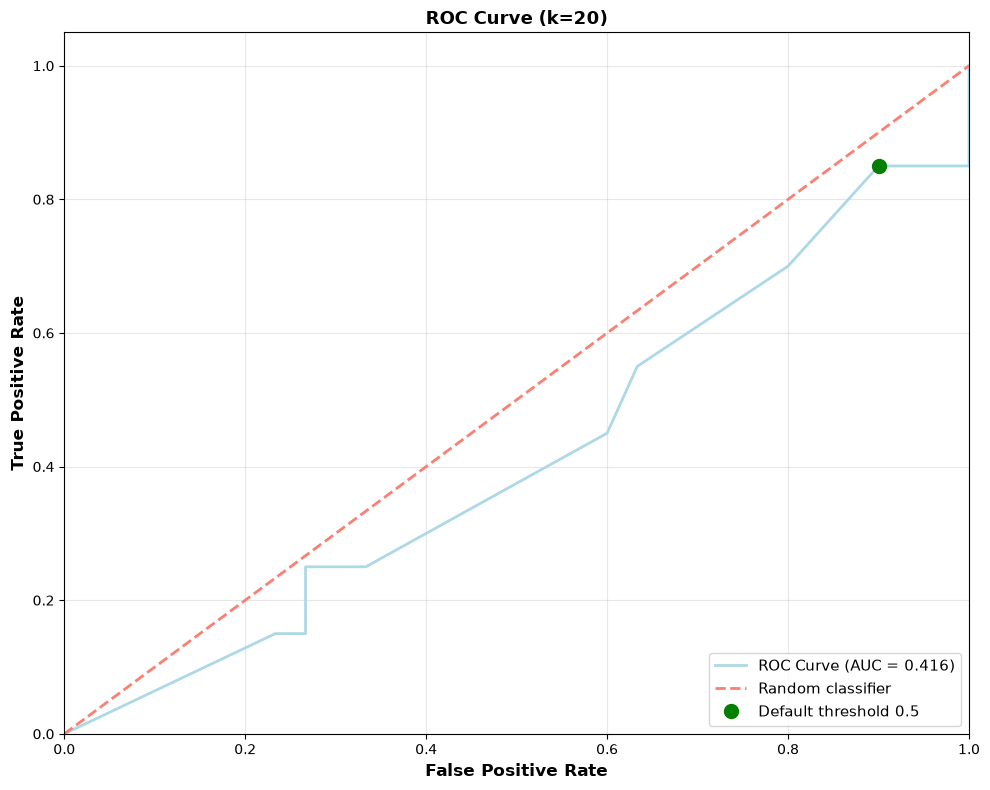


AUC Score: 0.4158
At default threshold (0.5):
True Positive Rate: 0.850 (detects 85.0% of resistants)
False Positive Rate: 0.900 (90.0% of susceptibles are misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_knn.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random classifier')

# Mark the default threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold 0.5')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (k={grid_search.best_params_["kneighborsclassifier__n_neighbors"]})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/05_knn_ROC", dpi=300)
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At default threshold (0.5):")
print(f"True Positive Rate: {tpr[default_idx]:.3f} (detects {tpr[default_idx]*100:.1f}% of resistants)")
print(f"False Positive Rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptibles are misclassified)")

## **5. Save Model Results**

In [14]:
import csv
import os

# Store results
results = {
    'model': 'K-Nearest Neighbors',
    'hyperparameters': f"k={grid_search.best_params_['kneighborsclassifier__n_neighbors']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = "Results/model_results.csv"

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: K-Nearest Neighbors
Hyperparameters: k=20
Test Accuracy: 0.4000
CV Score: 0.7278
